# pMoE on the fine-tuned ConvNeXt-Tiny: 20 experts, 4x4-pixel patches

**Question.** On the self-built ResNet every head stopped at the frozen backbone's limit (~23 % val). Does patch-level
routing (pMoE) add anything on a **strong** backbone?

**Set-up**
* Backbone: the fine-tuned **E7 ConvNeXt-Tiny** from `ConvNeXt_finetune.ipynb` (`ConvNeXt_finetune/models/E7-ConvNeXtTiny.weights.h5`), **frozen**.
* The 64x64 image is enlarged to **256x256** (E7 used 224). The output of ConvNeXt stage 3 is then a **16x16** grid of
  384 numbers; each cell covers **4x4 pixels** of the original image. These 256 cells are the patches. Stage 4 is not used.
* Head: **pMoE with 20 experts**; every expert has its own router, keeps its best `L_PATCHES` patches, and the experts' class scores are added.

| reference (validation set) | accuracy | macro-F1 |
|---|---|---|
| E6: ConvNeXt-Tiny (ImageNet) frozen + linear head | 65.2 % | |
| E7: ConvNeXt-Tiny fine-tuned + linear head (the backbone used here) | 71.2 % | 0.676 |

Caveats: the backbone is ImageNet-pretrained and was fine-tuned on this training set (best epoch chosen on this
validation set), and at 256 px objects look ~14 % larger than in its fine-tuning. Compare the pMoE with E7, not with the ResNet runs.

**How to run.** Top to bottom. The cell you may want to edit is **Settings**. `USE_SAVED = True` (first code cell)
loads the saved head weights and log instead of training. The E7 weights file (~110 MB) is too large for GitHub: on a
new pod, copy it to the same path first (see the backbone cell).

Everything this notebook needs is defined in it; only the data and GitHub helpers come from `utils/`.
Only the validation split is used.

In [20]:
!nvidia-smi

Sun Nov 22 00:24:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.14              Driver Version: 550.54.14      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX A6000               Off |   00000000:41:00.0 Off |                  Off |
| 42%   69C    P2            137W /  300W |   47178MiB /  49140MiB |     48%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
USE_SAVED = False   # True: load the saved head weights and log instead of training (analyse an old run)

import os, sys, subprocess
import warnings
warnings.filterwarnings('ignore')
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
#os.environ.setdefault('TF_FORCE_GPU_ALLOW_GROWTH', 'true')   # take GPU memory as needed, not all of it at start (kernels can then share a GPU)

REPO_URL = 'https://github.com/durak-dev/ImageClassification.git'
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Colab starts with an empty VM: clone the repo (code AND data live in it).
    # On later runs the folder already exists, so just pull the newest commits.
    ROOT = '/content/ImageClassification'
    if not os.path.exists(ROOT):
        subprocess.run(['git', 'clone', REPO_URL, ROOT], check=True)
    else:
        # fetch + hard reset instead of `pull`: always lands on the newest origin commit, even if the VM copy diverged
        subprocess.run(['git', '-C', ROOT, 'fetch', 'origin'], check=True)
        subprocess.run(['git', '-C', ROOT, 'reset', '--hard', '@{u}'], check=True)
else:
    # Local: the notebook sits in the project root, but also work if it was
    # started from a subfolder.
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, 'utils')) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)          # so `import utils.funcs` finds OUR utils folder

DATA_DIR = os.path.join(ROOT, 'data')
ORIG_DIR = os.path.join(DATA_DIR, 'original')            # raw images/ + labels/ (placed manually, never modified)
MANIFEST_PATH = os.path.join(DATA_DIR, 'split_manifest.csv')   # which file belongs to which split
SEED = 42
NB_DIR = 'pMoE_ConvNeXt'   # this notebook's output folder (relative to the project root)
MODELS_DIR = f'{NB_DIR}/models'          # head weights (normalisation + pMoE layer)
HISTORY_DIR = f'{NB_DIR}/history_logs'   # one CSV log per training run
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)
print('Running on:', 'Google Colab' if IN_COLAB else 'local machine')
print('Project root:', ROOT)

Running on: local machine
Project root: /home/20240644


In [4]:
# the kernel survives between runs: drop every cached utils module so the code git just pulled is what gets imported
for _m in [m for m in sys.modules if m == 'utils' or m.startswith('utils.')]:
    del sys.modules[_m]
from utils.funcs import SPLITS, CORRECTED_LABELS_FILE, split_dir, materialize_splits, rebuild_corrected, balance_frame
from utils import config, github_sync

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score
keras.mixed_precision.set_global_policy('mixed_float16')   # ~2x faster on the GPU

I0000 00:00:1795305280.580018  898537 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795305280.619931  898537 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795305281.743328  898537 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Where the results go
The log goes to `pMoE_ConvNeXt/history_logs/`, the head weights to `pMoE_ConvNeXt/models/` (only the trained layers, ~3 MB:
the backbone always comes from the E7 file). On a RunPod pod or Colab VM the disk is lost when it ends, so the next cell offers:
* **Push to GitHub:** paste a GitHub token (hidden, kept in memory only). The log and head weights are committed to the `checkpoints` branch when they are written. Leave the box empty to skip.
* **Copy to your PC:** run `.\pull_results.ps1 -Ip <ip> -Port <port>` before you terminate the pod (see the README).

In [5]:
# Is the disk temporary? Colab VM, or a RunPod pod (pod_bootstrap.sh clones the repo into /workspace).
ON_POD = ROOT.startswith('/workspace/') or bool(os.environ.get('RUNPOD_POD_ID'))
REMOTE = IN_COLAB or ON_POD
if REMOTE:
    config.ensure_github()      # asks once for a GitHub token (hidden box, kept in memory only); empty = no upload
USE_GITHUB = REMOTE and config.github_ready()

if USE_GITHUB:
    _, repo, branch = config.github_settings()
    print(f'Results -> GitHub {repo}@{branch}: the log and head weights are committed when they are written')
elif ON_POD:
    print('Results stay on the pod. Copy them to your PC before terminating it:  .\\pull_results.ps1 -Ip <ip> -Port <port>')
else:
    print(f'Results -> local folders ({HISTORY_DIR}/, {MODELS_DIR}/)')

Results -> local folders (pMoE_ConvNeXt/history_logs/, pMoE_ConvNeXt/models/)


In [6]:
# Recreate data/{split}/ with the corrected images + labels if they are missing (fresh Colab VM).
# Needs split_manifest.csv, data/original/ and the two checkpoint files from the cloned repo.
if not all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, 'labels'), CORRECTED_LABELS_FILE)) for s in SPLITS):
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(pd.read_csv(os.path.join(ROOT, 'checkpoints', 'df_fixed.csv')), DATA_DIR,
                      labels_corrected=pd.read_csv(os.path.join(ROOT, 'checkpoints', 'labels_corrected.csv')))

In [7]:
dfs = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in ["train", "val", "test"]}
classes = sorted(dfs["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

## Data
Images are resized to 64x64. **Only the training set is rebalanced** (classes with few images are repeated up to the median class size); validation and test stay as they are.

In [8]:
SIZE, BATCH, AUTOTUNE = 64, 128, tf.data.AUTOTUNE   # 128: every image goes through ConvNeXt at 256x256
CLASS_BALANCE = 'oversample'         # train set only: None | "oversample" | "undersample"  (see funcs.balance_frame)
CLASS_BALANCE_TARGET = 'median'  # images per class: None (max / min) | "min" | "median" | "max" | int

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (SIZE, SIZE))
    return tf.cast(tf.round(img), tf.uint8), y        # uint8: 4x smaller in the RAM cache below

def make_ds(split, shuffle):
    df = dfs[split]
    if split == "train" and CLASS_BALANCE:      # never resample val / test
        df = balance_frame(df, CLASS_BALANCE, CLASS_BALANCE_TARGET, seed=SEED)
        n = df["class_id"].value_counts()
        print(f"train balanced ({CLASS_BALANCE}): {len(df)} images, {n.min()}-{n.max()} per class")
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    labels = df["class_id"].map(class_to_idx)
    assert labels.notna().all(), f"{split} has labels not present in train"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels.values.astype("int32")))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()   # decode + resize ONCE; later epochs read from RAM
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)                  # after cache(), so the order still changes every epoch
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train, val, test = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(len(classes), "classes")
print(dfs["train"]["filename"].iloc[0], os.path.exists(f"{DATA_DIR}/train/images_corrected/" + str(dfs["train"]["filename"].iloc[0])))
for x, y in train.take(1):
    print(x.shape, x.dtype, float(tf.reduce_min(x)), float(tf.reduce_max(x)))

train balanced (oversample): 38600 images, 193-193 per class


I0000 00:00:1795305290.791100  898537 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12550 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:41:00.0, compute capability: 8.6


200 classes
image_000002.JPEG True
(128, 64, 64, 3) <dtype: 'float32'> 0.0 255.0


## Settings
* **Patches:** `INPUT_SIZE = 256` makes the stage-3 map 16x16, so one patch = 4x4 pixels (224 would give 14x14, ~4.6 pixels).
* **pMoE:** `N_EXPERTS` experts, each keeps `L_PATCHES` of the 256 patches, `HIDDEN` units per expert.
* Training: at most `EPOCHS` epochs, 1 epoch warmup to `LR` then cosine decay to 0; early stopping after `PATIENCE`
  epochs without a better validation loss (the best epoch is kept).

In [9]:
# ======== Settings ========
E7_WEIGHTS = 'ConvNeXt_finetune/models/E7-ConvNeXtTiny.weights.h5'   # weights of the fine-tuned E7 model
INPUT_SIZE = 256          # images are enlarged to this inside the model; 256 -> 16x16 patches of 4x4 pixels

N_EXPERTS = 20            # pMoE experts
L_PATCHES = 16            # patches each expert keeps (of 16 x 16 = 256)
HIDDEN = 64               # units of each expert's hidden layer
FEATURE_DROP = 0.3        # SpatialDropout2D on the feature map, before the router (whole channels)
EXPERT_DROP = 0.3         # dropout inside each expert

EPOCHS = 10               # at most (early stopping)
PATIENCE = 4              # epochs without a better val loss before stopping
LR = 1e-3                 # PEAK learning rate (warmup + cosine)
WEIGHT_DECAY = 1e-4       # AdamW; not on biases
USE_AUG = True            # random flip + shift

RUN_NAME = f'pmoe_e{N_EXPERTS}_l{L_PATCHES}_{INPUT_SIZE}px_E7'   # log + weight file names

AUG = keras.Sequential([layers.RandomFlip('horizontal'), layers.RandomTranslation(0.1, 0.1)], name='aug') if USE_AUG else None
STEPS = int(train.cardinality())   # batches per epoch
HEAD_LR = keras.optimizers.schedules.CosineDecay(0.0, decay_steps=(EPOCHS - 1) * STEPS, warmup_target=LR, warmup_steps=STEPS)
Y_VAL = np.concatenate([y.numpy() for _, y in val])   # val is not shuffled: same order as model.predict(val)

## The backbone: E7 ConvNeXt-Tiny, frozen, up to stage 3
1. The E7 model is rebuilt exactly as `ConvNeXt_finetune.ipynb` built it (so the weights file fits) and its weights are loaded.
2. The same weights are copied into a ConvNeXt-Tiny for `INPUT_SIZE` (ConvNeXt has no position-dependent weights, so any size works).
3. The backbone used here ends at the **input of the last downsampling layer** = the output of stage 3 (16x16x384 at 256 px).
   (Keras names the residual branch of each block `..._identity`; the residual sum has no layer of its own, which is why
   the stage output is read as the next layer's input.)

The backbone is frozen and always runs in inference mode.

In [10]:
if not os.path.exists(E7_WEIGHTS):
    raise FileNotFoundError(
        f'{E7_WEIGHTS} is missing. It is too large for GitHub (~110 MB): copy it from your PC to the same path, e.g.\n'
        f'  scp -P <port> {E7_WEIGHTS} root@<ip>:{ROOT}/{E7_WEIGHTS}')

# 1. E7 as ConvNeXt_finetune.build_model built it
e7_cnx = keras.applications.ConvNeXtTiny(include_top=False, include_preprocessing=True, weights=None,
                                         input_shape=(224, 224, 3), pooling='avg')
e7_aug = keras.Sequential([layers.RandomFlip('horizontal', dtype='float32'), layers.RandomTranslation(0.1, 0.1, dtype='float32'),
                           layers.RandomZoom(0.2, dtype='float32'), layers.RandomRotation(0.05, dtype='float32'),
                           layers.RandomContrast(0.2, dtype='float32')], name='augment')
e7_in = keras.Input((SIZE, SIZE, 3))
x = layers.Dropout(0.3)(e7_cnx(layers.Resizing(224, 224, dtype='float32')(e7_aug(e7_in))))
e7 = keras.Model(e7_in, layers.Dense(len(classes), activation='softmax', dtype='float32', name='classifier')(x))
e7.load_weights(E7_WEIGHTS)

# 2. the same weights for INPUT_SIZE
cnx = keras.applications.ConvNeXtTiny(include_top=False, include_preprocessing=True, weights=None,
                                      input_shape=(INPUT_SIZE, INPUT_SIZE, 3), pooling='avg')
cnx.set_weights(e7_cnx.get_weights())
assert all(np.array_equal(a, b) for a, b in zip(cnx.get_weights(), e7_cnx.get_weights()))

# 3. stop after stage 3
CONVNEXT = keras.Model(cnx.input, cnx.get_layer('convnext_tiny_downsampling_block_2').input, name='convnext_stage3')
CONVNEXT.trainable = False
del e7, e7_cnx, e7_aug, cnx
print('feature map (H, W, C):', tuple(CONVNEXT.output.shape[1:]), f'| {SIZE // CONVNEXT.output.shape[1]}x{SIZE // CONVNEXT.output.shape[1]} pixels per patch',
      f'| backbone weights {CONVNEXT.count_params():,} (frozen)')

E0000 00:00:1795305301.569932  898537 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


feature map (H, W, C): (16, 16, 384) | 4x4 pixels per patch | backbone weights 12,348,000 (frozen)


## The pMoE layer
Adapted from *Patch-level Routing in Mixture-of-Experts* (Chowdhury et al., ICML 2023):
```
for every expert:
    router:  one vector; scores all 256 patches and keeps the best L_PATCHES
    expert:  Dense(HIDDEN, ReLU) -> dropout on each kept patch, average weighted by the softmax of the kept scores,
             Dense(200) -> class scores
output = sum of the experts' scores
```
Nothing forces the experts to choose different patches; the plots after training show whether they do.

In [11]:
class PatchMoE(layers.Layer):
    def __init__(self, n_experts, n_classes, l, hidden=64, drop=0.0, **kw):
        super().__init__(**kw)
        self.n_experts, self.n_classes, self.l, self.hidden, self.drop = n_experts, n_classes, l, hidden, drop

    def build(self, input_shape):
        _, h, w, c = input_shape
        self.grid, self.n_patches, self.channels = (h, w), h * w, c
        if self.l > self.n_patches:
            raise ValueError(f'l={self.l} but the feature map only has {self.n_patches} patches ({h}x{w})')
        self.router = self.add_weight(name='router', shape=(self.n_experts, c),
                                      initializer=keras.initializers.RandomNormal(stddev=0.02))
        self.hidden_layers = [layers.Dense(self.hidden, activation='relu') for _ in range(self.n_experts)]
        self.drop_layers = [layers.Dropout(self.drop) for _ in range(self.n_experts)]
        self.out_layers = [layers.Dense(self.n_classes) for _ in range(self.n_experts)]
        for i in range(self.n_experts):
            self.hidden_layers[i].build((None, self.l, c))
            self.out_layers[i].build((None, self.hidden))

    def route(self, feature_map):
        """patches (batch, n, C), top_idx (batch, experts, l) = patches kept by each expert, gates (batch, experts, l)."""
        patches = tf.reshape(feature_map, (tf.shape(feature_map)[0], self.n_patches, self.channels))
        scores = tf.einsum('bnc,kc->bkn', patches, tf.cast(self.router, patches.dtype))   # (batch, experts, n)
        top_scores, top_idx = tf.math.top_k(scores, k=self.l)                             # best l patches PER expert
        return patches, top_idx, tf.nn.softmax(top_scores, axis=-1)

    def call(self, feature_map, training=None):
        patches, top_idx, gates = self.route(feature_map)
        chosen = tf.gather(patches, top_idx, batch_dims=1)                                # (batch, experts, l, C)
        scores = []
        for i in range(self.n_experts):
            h = self.drop_layers[i](self.hidden_layers[i](chosen[:, i]), training=training)   # (batch, l, hidden)
            scores.append(self.out_layers[i](tf.reduce_sum(h * gates[:, i, :, None], axis=1)))
        return tf.add_n(scores)

## Training
`run` trains the model and keeps the best epoch (lowest validation loss). Each epoch it also computes the validation
**macro-F1** (every class counts the same). The log goes to `history_logs/<RUN_NAME>.csv`, the weights of the trained layers (normalisation + pMoE) to
`models/<RUN_NAME>.weights.npz`. With `USE_SAVED = True` both are loaded instead (from GitHub if they are not on this disk).

In [12]:
class MacroF1(keras.callbacks.Callback):
    """Adds val_f1 (macro-F1 on the validation set) to the epoch logs; listed before CSVLogger so it lands in the CSV."""
    def on_epoch_end(self, epoch, logs=None):
        logs['val_f1'] = f1_score(Y_VAL, self.model.predict(val, verbose=0).argmax(1), average='macro')
        print(f' - val_f1: {logs["val_f1"]:.4f}')


def run(model, name):
    log_path, weights_path = f'{HISTORY_DIR}/{name}.csv', f'{MODELS_DIR}/{name}.weights.npz'
    head = [model.get_layer('feature_norm'), model.get_layer('pmoe')]   # the trained layers (the backbone comes from E7_WEIGHTS)
    if USE_SAVED:
        for p in (log_path, weights_path):
            if not os.path.exists(p) and USE_GITHUB:
                with open(p, 'wb') as f:
                    f.write(github_sync.fetch_file(p))
            if not os.path.exists(p):
                raise FileNotFoundError(f'{p} is missing: train this run first (USE_SAVED = False)')
        saved = np.load(weights_path)
        weights = [saved[f'arr_{i}'] for i in range(len(saved.files))]
        head[0].set_weights(weights[:2]); head[1].set_weights(weights[2:])
        history = pd.read_csv(log_path)
    else:
        model.fit(train, validation_data=val, epochs=EPOCHS, callbacks=[
            MacroF1(),
            keras.callbacks.CSVLogger(log_path),
            keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)])
        np.savez(weights_path, *head[0].get_weights(), *head[1].get_weights())
        if USE_GITHUB:
            github_sync.push_files({log_path: log_path, weights_path: weights_path}, f'run: {name}')
        history = pd.read_csv(log_path)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for a, metric in zip(ax[:2], ['loss', 'accuracy']):
        a.plot(history[metric], marker='o', label='train')
        a.plot(history[f'val_{metric}'], marker='o', label='validation')
        a.set(title=metric, xlabel='epoch'); a.legend()
    ax[2].plot(history['val_f1'], marker='o')
    ax[2].set(title='validation macro-F1', xlabel='epoch')
    plt.tight_layout(); plt.show()
    return history

## pMoE: 20 experts on 4x4-pixel patches
```
64x64 image -> augmentation -> resize to 256 -> ConvNeXt stages 1-3 (frozen) -> 16x16x384 -> pMoE (20 experts) -> 200 class scores
```
The stage-3 output is ConvNeXt's running residual sum and is not normalised (ConvNeXt itself normalises it in the
next downsampling layer), so a `LayerNormalization` (trainable, 768 weights) brings each patch to a normal scale first.

trainable weights: 761,248 (normalisation + pMoE)
Epoch 1/10


I0000 00:00:1795305326.048844  900381 cuda_dnn.cc:461] Loaded cuDNN version 92000
I0000 00:00:1795305326.507011  900381 service.cc:153] XLA service 0x7f20ef9c5ef0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795305326.507030  900381 service.cc:161]   StreamExecutor [0]: NVIDIA RTX A6000, Compute Capability 8.6 (Driver: 12.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
E0000 00:00:1795305327.635549  900381 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1795305330.690053  900381 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.0195 - loss: 5.9258 - val_f1: 0.0981
302/302 ━━━━━━━━━━━━━━━━━━━━ 129s 364ms/step - accuracy: 0.0195 - loss: 5.9258 - val_accuracy: 0.1458 - val_loss: 4.4783 - val_f1: 0.0981
Epoch 2/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.2454 - loss: 3.7773 - val_f1: 0.3645
302/302 ━━━━━━━━━━━━━━━━━━━━ 94s 312ms/step - accuracy: 0.2454 - loss: 3.7773 - val_accuracy: 0.4117 - val_loss: 2.8984 - val_f1: 0.3645
Epoch 3/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.4058 - loss: 2.9406 - val_f1: 0.4348
302/302 ━━━━━━━━━━━━━━━━━━━━ 94s 312ms/step - accuracy: 0.4058 - loss: 2.9406 - val_accuracy: 0.4778 - val_loss: 2.6240 - val_f1: 0.4348
Epoch 4/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.4769 - loss: 2.6125 - val_f1: 0.4571
302/302 ━━━━━━━━━━━━━━━━━━━━ 94s 313ms/step - accuracy: 0.4769 - loss: 2.6125 - val_accuracy: 0.4973 - val_loss: 2.5255 - val_f1: 0.4571
Epoch 5/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s

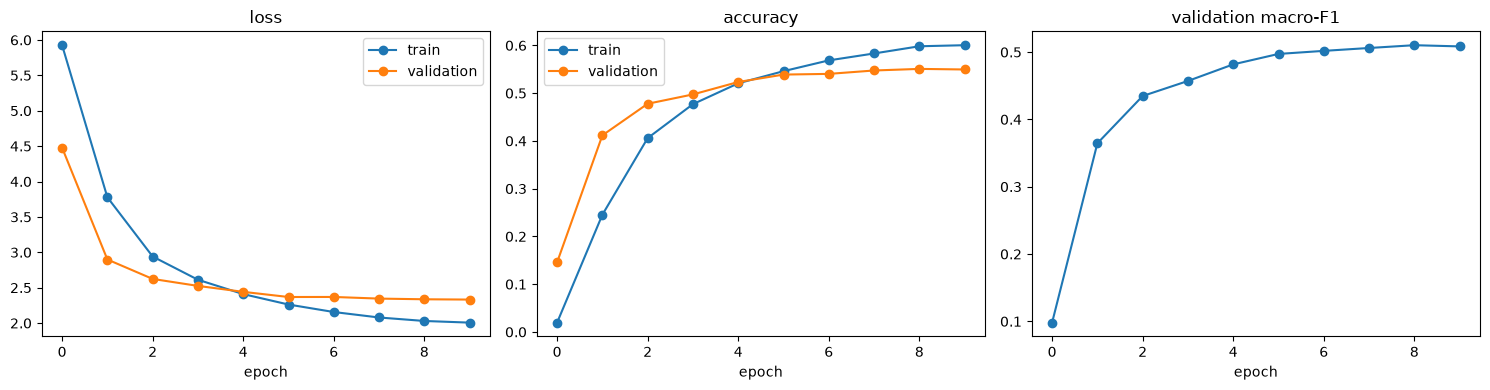

In [13]:
inp = keras.Input((SIZE, SIZE, 3))
x = AUG(inp) if AUG is not None else inp
x = layers.Resizing(INPUT_SIZE, INPUT_SIZE, dtype='float32')(x)
x = CONVNEXT(x, training=False)
x = layers.LayerNormalization(epsilon=1e-6, name='feature_norm')(x)   # stage 3 is ConvNeXt's un-normalised residual sum (values in the hundreds)
x = layers.SpatialDropout2D(FEATURE_DROP)(x)
x = PatchMoE(N_EXPERTS, len(classes), L_PATCHES, hidden=HIDDEN, drop=EXPERT_DROP, name='pmoe')(x)
model = keras.Model(inp, layers.Activation('linear', dtype='float32')(x), name=RUN_NAME)   # float32 scores for the loss

opt = keras.optimizers.AdamW(HEAD_LR, weight_decay=WEIGHT_DECAY)
opt.exclude_from_weight_decay(var_names=['bias'])
model.compile(opt, keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
print(f'trainable weights: {sum(int(np.prod(w.shape)) for w in model.trainable_weights):,} (normalisation + pMoE)')

history = run(model, RUN_NAME)

## Which patches do the experts pick?
One panel per expert for two validation images: the outlined 4x4-pixel squares are the patches that expert kept.

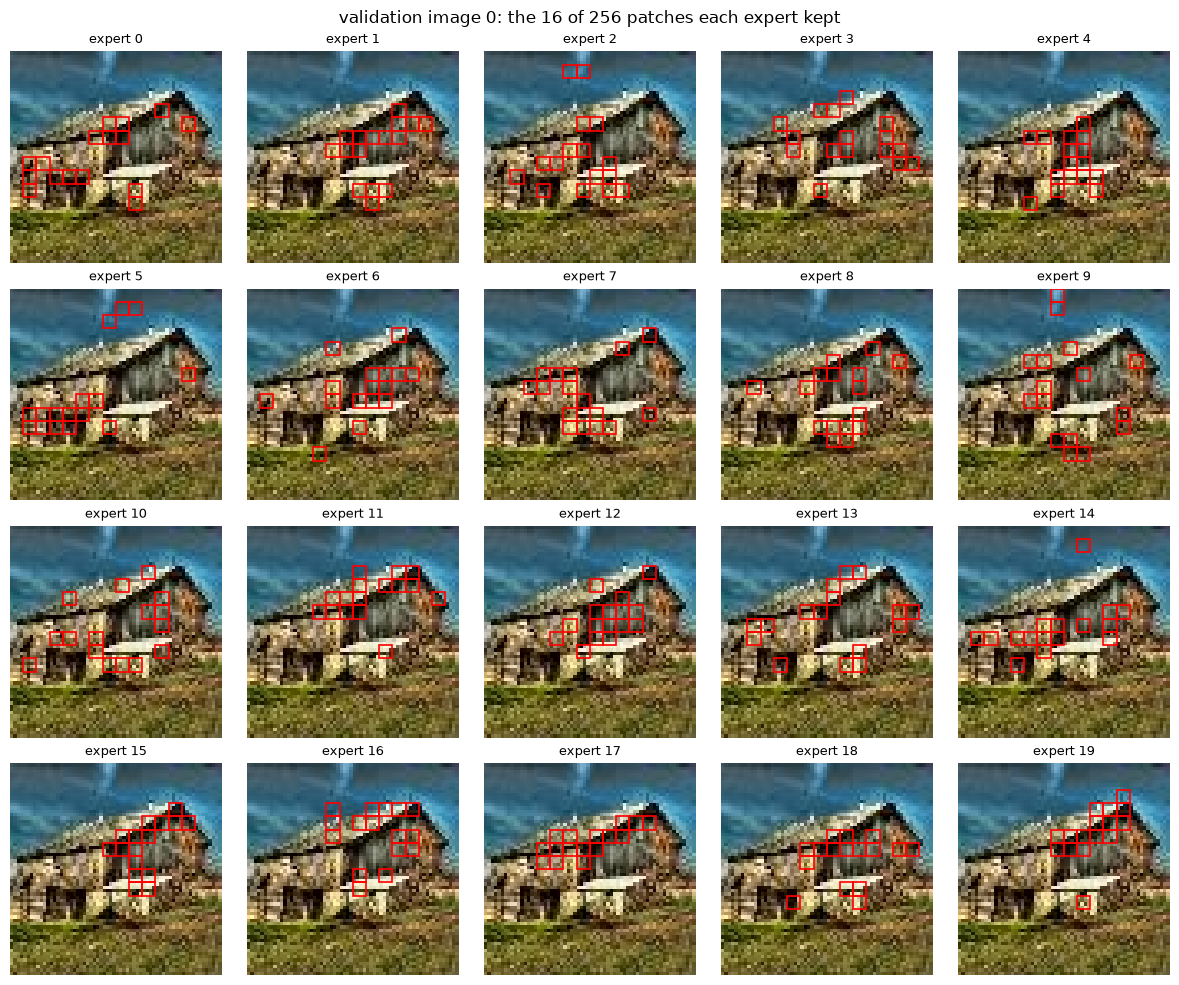

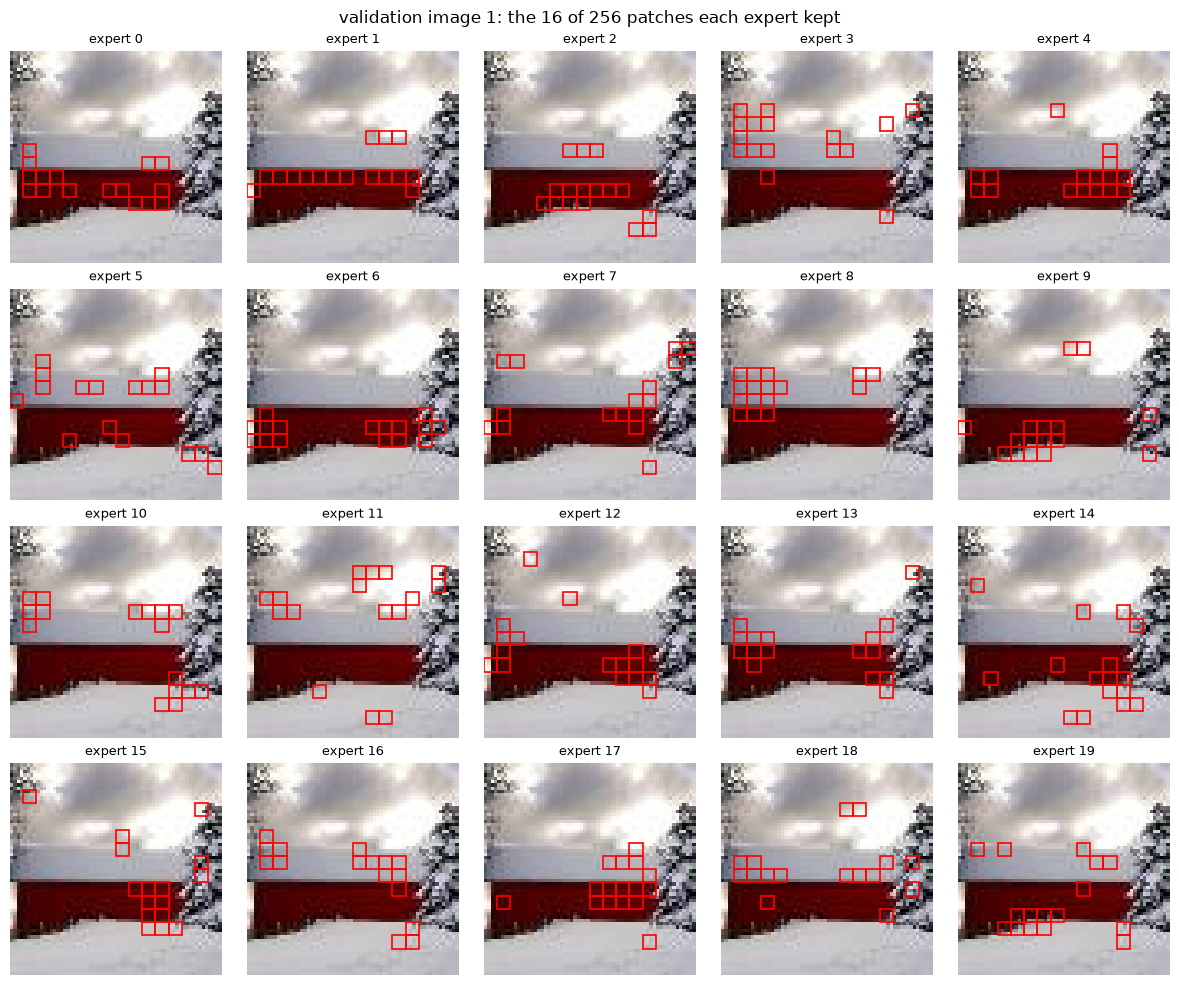

In [19]:
pmoe = model.get_layer('pmoe')
images = next(iter(val))[0][:64]
feature_map = keras.Model(model.input, pmoe.input).predict(images, verbose=0)
_, top_idx, gates = pmoe.route(tf.constant(feature_map, tf.float32))
top_idx = top_idx.numpy()                    # (images, experts, L_PATCHES)
grid_h, grid_w = pmoe.grid
cell = SIZE / grid_w                         # pixels per patch side

for i in range(2):
    fig, axes = plt.subplots(4, 5, figsize=(12, 10))
    for e, a in enumerate(axes.flat):
        a.imshow(images[i].numpy().astype('uint8'))
        for p in top_idx[i, e]:
            row, col = divmod(int(p), grid_w)
            a.add_patch(plt.Rectangle((col * cell - 0.5, row * cell - 0.5), cell, cell, fill=False, edgecolor='red', linewidth=1.2))
        a.set_title(f'expert {e}', fontsize=9); a.axis('off')
    fig.suptitle(f'validation image {i}: the {L_PATCHES} of {grid_h * grid_w} patches each expert kept')
    plt.tight_layout(); plt.show()

Do the experts specialise? Left: how many patches two experts share, averaged over 64 validation images (the diagonal
is `L_PATCHES`; large off-diagonal values = experts look at the same places). Right: how often each patch position is
picked by any expert (a bright centre and dark border means the experts concentrate on the middle of the image).

In [ ]:
kept = [[set(top_idx[n, e]) for e in range(N_EXPERTS)] for n in range(len(top_idx))]
shared = np.mean([[[len(s[a] & s[b]) for b in range(N_EXPERTS)] for a in range(N_EXPERTS)] for s in kept], axis=0)
position = np.bincount(top_idx.ravel(), minlength=grid_h * grid_w).reshape(grid_h, grid_w) / (len(top_idx) * N_EXPERTS)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(shared, vmin=0, vmax=L_PATCHES, cmap='Blues', square=True, ax=ax[0])
ax[0].set(title=f'Shared patches between experts (mean of {len(top_idx)} images)', xlabel='expert', ylabel='expert')
sns.heatmap(position, cmap='magma', square=True, xticklabels=False, yticklabels=False, ax=ax[1])
ax[1].set(title='How often each patch position is picked')
plt.tight_layout(); plt.show()
off = shared[~np.eye(N_EXPERTS, dtype=bool)]
print(f'two experts share {off.mean():.1f} of {L_PATCHES} patches on average (random choice would give {L_PATCHES ** 2 / (grid_h * grid_w):.1f})')

## Result
Best validation accuracy and macro-F1 of the pMoE, next to the linear head of E7 on the same (full, 224 px) backbone.

In [ ]:
pd.DataFrame([
    dict(model='E7: linear head, whole network fine-tuned (ConvNeXt_finetune)', best_val_acc=0.7120, best_val_f1=0.6757),
    dict(model=f'pMoE {N_EXPERTS} experts, {L_PATCHES} of {grid_h * grid_w} patches, frozen E7 stages 1-3',
         best_val_acc=history['val_accuracy'].max(), best_val_f1=history['val_f1'].max(),
         best_f1_epoch=int(history['val_f1'].values.argmax()) + 1, epochs_run=len(history),
         last_train_acc=history['accuracy'].iloc[-1]),
]).set_index('model').round(4)

### Notes
Fill in after running:
* best val accuracy / macro-F1 vs E7 (71.2 % / 0.676):
* do the experts pick different patches (shared-patches plot)?
* train vs validation gap:
* time per epoch: